In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa
import librosa.display
import sys

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from extract_modes import extract_exact_modes
from utils import plot_acoustic_comparison
from synth2 import PhysicalTombakSynthesizer

In [2]:
synth = PhysicalTombakSynthesizer(sr=44100)
stroke = 'hit_mid'
original_audio_path = f"../../single_stroke_analysis/data/raw/{stroke}/GIO_MEE_tombak_{stroke}.wav"
original_audio, sr = librosa.load(original_audio_path, sr=44100)

In [21]:
physical_params = {
    'striker_mass_kg': 0.05,
    'striker_velocity': 2.0,          
    'contact_stiffness': 5e4,
    'hertz_alpha': 1.5,
    'force_to_audio_scalar': 0.00001, # Extremely safe scaling
    
    'membrane_effective_mass': 0.1, 
    'membrane_stiffness': 1.5e4,
    'membrane_damping': 8.0,
    
    'friction_gain': 0.05,            
    'friction_decay': 50.0,

    'q_multiplier': 7,
    
    'tension_modulation_coeff': 0.005, 
    'energy_smoothing_hz': 40.0,
    
    'dry_exciter_mix': 0.005,
    'saturation_gain': 0.5            
}

In [4]:
exact_modes = extract_exact_modes(original_audio)

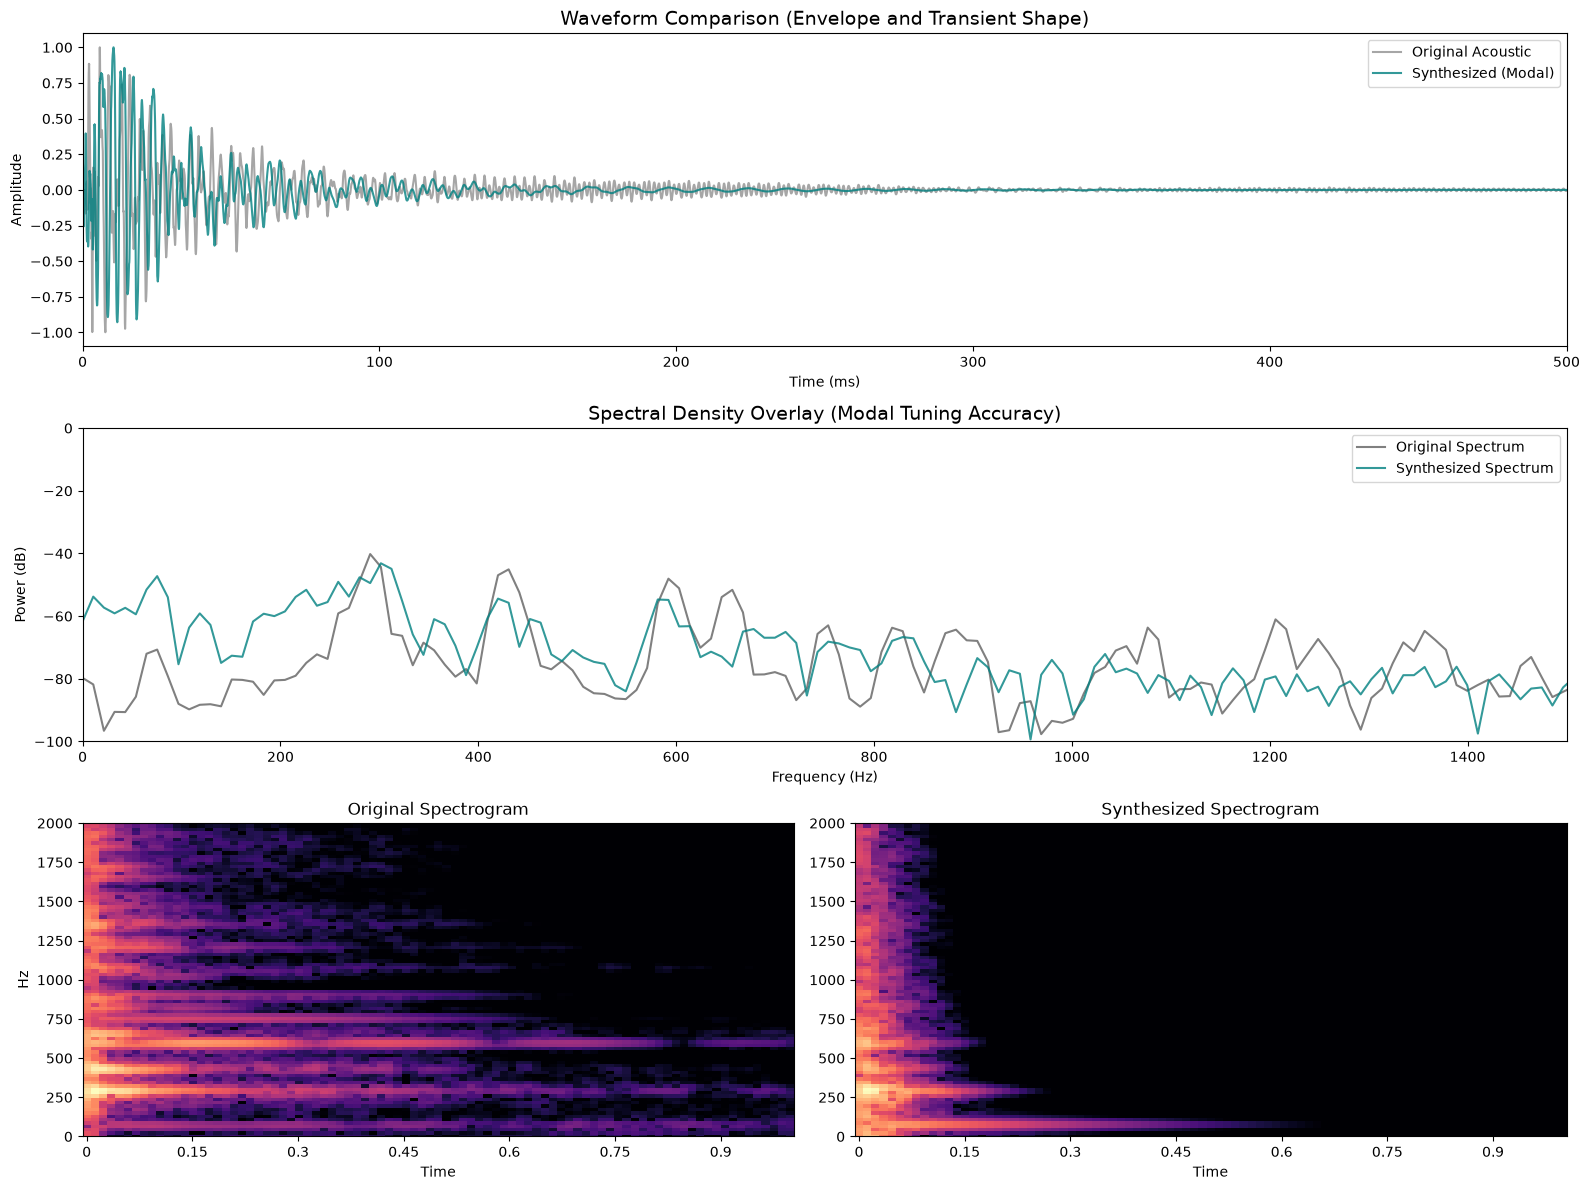

In [22]:
# 4. Synthesize the stroke
duration = 1.0
final_audio = synth.synthesize(modes=exact_modes, params=physical_params, duration=duration)
import IPython.display as ipd
display(ipd.Audio(final_audio, rate=sr))
display(ipd.Audio(original_audio, rate=sr))
plot_acoustic_comparison(original_audio, final_audio)